In [1]:
# install libraries

%pip install pandas sqlalchemy "psycopg[binary]" matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# import library

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\CHURNIQ\SQL\psql telco_customers_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.columns = df.columns.str.lower()

### Inspect columns and data types

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

Dataset shape: (7043, 21)

Column names:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']

Data types:


,Data Type
customerid,object
gender,object
seniorcitizen,int64
partner,object
dependents,object
tenure,int64
phoneservice,object
multiplelines,object
internetservice,object
onlinesecurity,object


### Check missing values

In [6]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
customerid,0,0.0
deviceprotection,0,0.0
totalcharges,0,0.0
monthlycharges,0,0.0
paymentmethod,0,0.0
paperlessbilling,0,0.0
contract,0,0.0
streamingmovies,0,0.0
streamingtv,0,0.0
techsupport,0,0.0


### Check duplicate records

In [7]:
print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs if the column exists
customer_id_col = next(
    (c for c in df.columns
     if c.lower() == "customerid"),
    
)

if customer_id_col:
    print(
        "Duplicate customer IDs:",
        df[customer_id_col].duplicated().sum()
    )
else:
    print("Customer ID column not found. Check Cell 7.")

Total duplicate rows: 0
Duplicate customer IDs: 0


### Clean column names and convert numeric columns

In [8]:
# Standardize column names for easier coding
df.columns = df.columns.str.strip()

# Convert TotalCharges to numeric if available
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# Convert SeniorCitizen to a categorical-friendly integer
if "SeniorCitizen" in df.columns:
    df["SeniorCitizen"] = pd.to_numeric(
        df["SeniorCitizen"],
        errors="coerce"
    )

print("Data types after cleaning:")
display(df.dtypes.to_frame(name="Data Type"))

Data types after cleaning:


,Data Type
customerid,object
gender,object
seniorcitizen,int64
partner,object
dependents,object
tenure,int64
phoneservice,object
multiplelines,object
internetservice,object
onlinesecurity,object


### Check the churn distribution

In [9]:
print(df.columns)

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='object')


In [10]:
print("Churn column values:")

if "churn" in df.columns:
    display(df["churn"].value_counts(dropna=False))
else:
     print("Churn column not found. Check df.columns.")

Churn column values:


churn
No     5174
Yes    1869
Name: count, dtype: int64

### Visualize the churn distribution

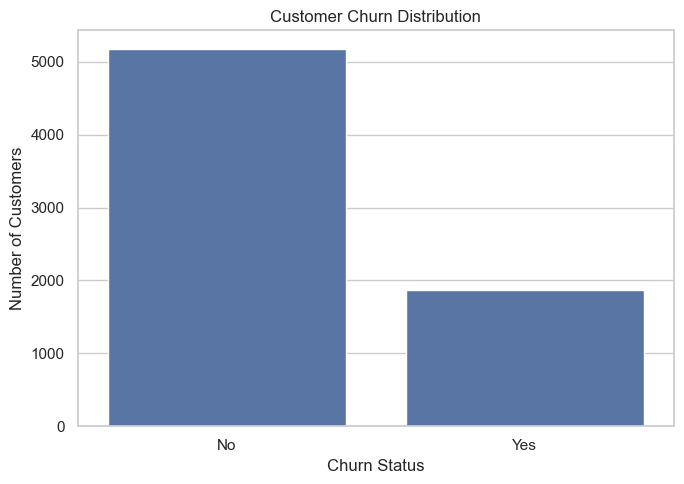

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

if "churn" in df.columns:
    plt.figure(figsize=(7, 5))

    ax = sns.countplot(
        data=df,
        x="churn"
    )

    ax.set_title("Customer Churn Distribution")
    ax.set_xlabel("Churn Status")
    ax.set_ylabel("Number of Customers")

    plt.tight_layout()
    plt.savefig("cust_churn_dist.png", dpi =300, bbox_inches= "tight")
    plt.show()
else:
    print("hi")

### Calculate the overall churn rate

In [12]:
if "churn" in df.columns:
    churn_rate = (
        df["churn"].astype(str).str.strip()
        .str.lower().eq("yes").mean() * 100
    )

    print(f"Overall churn rate: {churn_rate:.2f}%")

    print(
        f"Total customers: {len(df):,}"
    )
else:
    print("hi")

Overall churn rate: 26.54%
Total customers: 7,043


### Explore numerical feature

In [13]:
numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

print("Numerical columns:", numeric_cols)

display(df[numeric_cols].describe().T)

Numerical columns: ['seniorcitizen', 'tenure', 'monthlycharges']


,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


### Compare tenure between churned and retained customers

,count,mean,median,min,max
churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


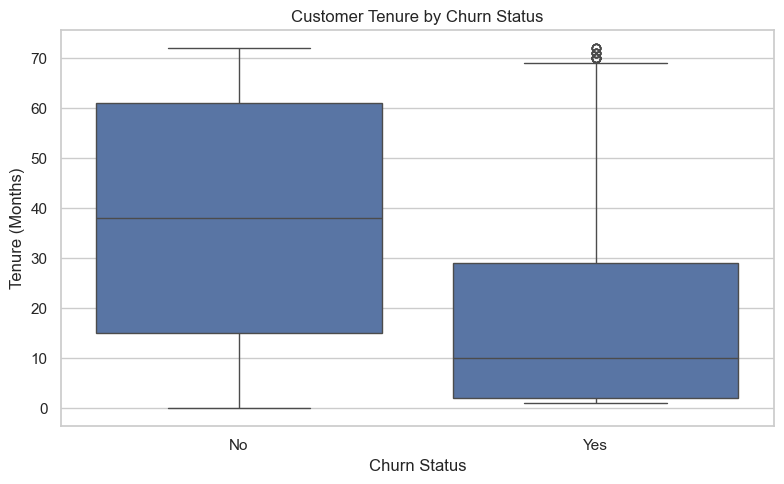

In [22]:
if {"churn", "tenure"}.issubset(df.columns):
    tenure_summary = (
        df.groupby("churn", observed=True)["tenure"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

    display(tenure_summary)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="churn",
        y="tenure"
    )

    plt.title("Customer Tenure by Churn Status")
    plt.xlabel("Churn Status")
    plt.ylabel("Tenure (Months)")
    plt.tight_layout()
    plt.savefig("cust_tenure_by_churn.png", dpi =300, bbox_inches= "tight")
    plt.show()

### Compare monthly charges by churn status

,mean,median,min,max
churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


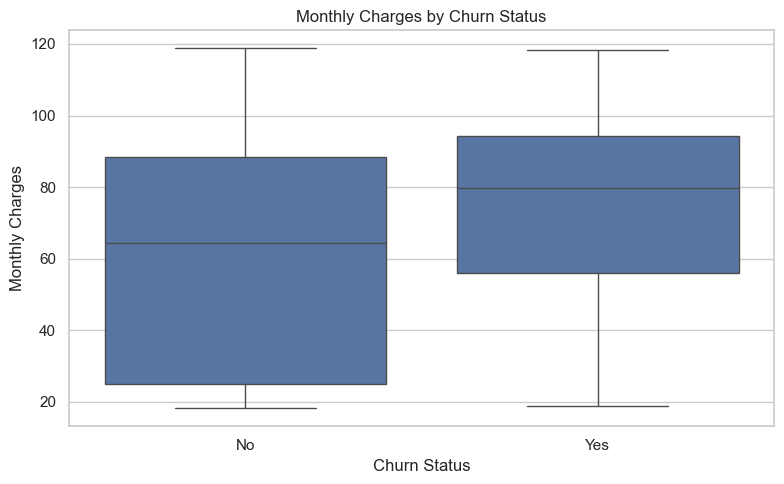

In [23]:
if {"churn", "monthlycharges"}.issubset(df.columns):
    charges_summary = (
        df.groupby("churn", observed=True)["monthlycharges"]
        .agg(["mean", "median", "min", "max"])
        .round(2)
    )

    display(charges_summary)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="churn",
        y="monthlycharges"
    )

    plt.title("Monthly Charges by Churn Status")
    plt.xlabel("Churn Status")
    plt.ylabel("Monthly Charges")
    plt.tight_layout()
    plt.savefig("monthly_charges.png", dpi =300, bbox_inches= "tight")
    plt.show()
else:
    print("hi")